# Bird or plane?

According to the literature square loss in conjunction with a logistic layer leads to small gradients and thus to slow learning. Cross-entropy loss remedies that. Let's verify it.

The idea is to take a more demanding dataset, the [CIFAR10](https://www.cs.toronto.edu/%7Ekriz/cifar.html) dataset.

First, we do a couple of necessary imports.

In [ ]:
import tensorflow as tf
import tensorflow.keras as keras
from sklearn.utils import shuffle
import numpy as np
import time
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")

We load the dataset with a convenient in-built method of tensorflow. We put all data in <code>X</code>, all classes in <code>y</code> and then scale so that the data has range $[0,1]$.

In [ ]:
data = tf.keras.datasets.cifar10
(x1, y1), (x2, y2) = data.load_data()
X=np.vstack([x1,x2])
y=np.vstack([y1,y2]).reshape(-1,)
X=X/255. # normalise so that all values in [0,1]
X.shape,y.shape

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


((60000, 32, 32, 3), (60000,))

We restrict to a binary classification problem: is it a bird or an airplane?

In [ ]:
X_bin=X[(y==0) | (y==2)]
y_bin=y[(y==0) | (y==2)]/2 # divide by 2, in order to get classes 0,1

We further simplify by turning the colour images into gray scale images. Let's visualise some samples.

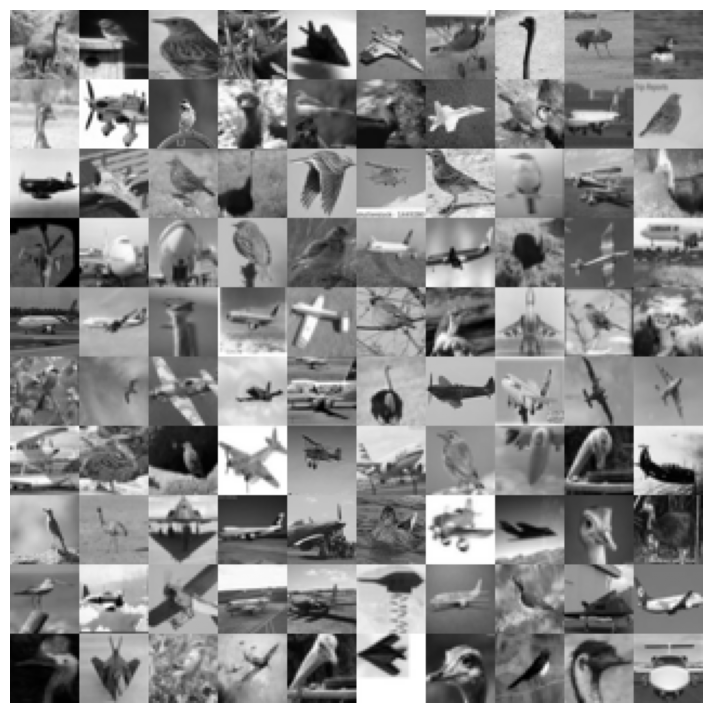

((12000, 32, 32), (12000,))

In [ ]:
def to_grayscale(img):
    return 1-(0.299*img[:,:,0]+0.587*img[:,:,1]+0.114*img[:,:,2])
X_bin=np.array([to_grayscale(img) for img in X_bin])

def show_samples(X,N=10):
    rows=[]
    for j in range(N):
        data=[X[i] for i in range(j*N,(j+1)*N)]
        rows.append(np.hstack(data))
    block=np.vstack(rows)

    # now we plot the array
    fig,ax=plt.subplots(figsize=(9,9))
    ax.imshow(block, cmap = "binary")
    ax.axis("off")
    plt.show()
show_samples(X_bin)
# let's see whether data is in the form we think it should be in
X_bin.shape,y_bin.shape

Next, let's write a method that draws a training and a test set from the data.

In [ ]:
train_size=7000
def get_datasets():
    XX,yy=shuffle(X_bin,y_bin)
    x_bin_train,x_bin_test=XX[:train_size],XX[train_size:]
    y_bin_train,y_bin_test=yy[:train_size],yy[train_size:]
    return x_bin_train,y_bin_train,x_bin_test,y_bin_test

We also write a method to set up a very simple neural network.

In [ ]:
def get_model():
    model = tf.keras.models.Sequential([
      tf.keras.layers.Flatten(input_shape=(32, 32)),
      tf.keras.layers.Dense(80, activation='relu'),
      tf.keras.layers.Dense(40, activation='relu'),
      tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    return model



### Compare square loss and cross-entropy loss
* We train a neural network as defined in <code>get_model</code> with square loss, and finetune the learning rate. That is, we try out different learning rates and pick the best one.
* We do the same for a neural network with cross-entropy loss.
* Next, with the finetuned learning rate, we train some square loss networks and a cross-entropy network for a number of epochs that seems appropriate.
* Lastly, we take the median of training and test accuracy and plot the result.


In [ ]:
# we first try to find an optimal learning rate

In [ ]:
REPEATS=5
EPOCHS=20
# num_grads=1000

loss_X = tf.keras.losses.BinaryCrossentropy()
loss_mse = tf.keras.losses.MeanSquaredError()
start=time.time()


learning_rates = [0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
# histories = {}


def run_model(x_bin_train, y_bin_train, x_bin_test, y_bin_test, learning_rate,loss, name):
      print(" > {} fit ".format(name),end="")
      model=get_model()
      model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=learning_rate),loss=loss, metrics=['accuracy'])
      # x_grad,y_grad=x_bin_train[:num_grads],y_bin_train[:num_grads]
      # grad_tracker=Grad_Tracker(model,loss,x_grad,y_grad)
      history=model.fit(x_bin_train, y_bin_train, epochs=EPOCHS,validation_data=(x_bin_test,y_bin_test),verbose=1)
      print("- {:.1f} s".format(time.time()-start),end="")

      # return history,grad_tracker
      return history

def models_X(learning_rate, repeats = REPEATS, epochs = EPOCHS):
  histories = {}
  for i in range(1, repeats + 1):
    x_bin_train,y_bin_train,x_bin_test,y_bin_test=get_datasets()
    history = run_model(x_bin_train, y_bin_train, x_bin_test, y_bin_test, learning_rate, loss_X, "cross entropy")
    print(f"Iteration {i}")
    histories[i] = history
    print("")
  return histories

def models_MSE(learning_rate, repeats = REPEATS, epochs = EPOCHS):
  histories = {}
  for i in range(1, repeats + 1):
    x_bin_train,y_bin_train,x_bin_test,y_bin_test=get_datasets()
    history = run_model(x_bin_train, y_bin_train, x_bin_test, y_bin_test, learning_rate, loss_mse, "mse")
    print(f"Iteration {i}")
    histories[i] = history
    print("")
  return histories

histories_X = {}
histories_MSE = {}
for lr in learning_rates:
  histories_X[lr] = models_X(lr)
  histories_MSE[lr] = models_MSE(lr)

# for lr in learning_rates:
#   my_SGD=tf.keras.optimizers.SGD(learning_rate=lr)
#   model.compile(loss=loss_X, metrics = ['accuracy'], optimizer = my_SGD)

#   history = model.fit(x_bin_train, y_bin_train, epochs=30, validation_data=(x_bin_test, y_bin_test))
#   histories[lr] = history


 > cross entropy fit Epoch 1/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5703 - loss: 0.6792 - val_accuracy: 0.6234 - val_loss: 0.6535
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6369 - loss: 0.6395 - val_accuracy: 0.6590 - val_loss: 0.6267
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6483 - loss: 0.6285 - val_accuracy: 0.6776 - val_loss: 0.6102
Epoch 4/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6640 - loss: 0.6167 - val_accuracy: 0.6872 - val_loss: 0.6012
Epoch 5/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6823 - loss: 0.5997 - val_accuracy: 0.6606 - val_loss: 0.6151
Epoch 6/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6800 - loss: 0.6034 - val_accuracy: 0.7050 - val_loss: 0.5896
Epoch 7/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6927 - loss: 0.5901 - val_accuracy: 0.7080 - val_loss: 0.5741
Epoch 8/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7031 - loss: 0.57

In [ ]:
#we calculate now the median of the accuracies in order to know which learning rate is better
median_train_acc_X = {}
median_val_acc_X = {}

for lr in learning_rates:
    all_train_acc = []
    all_val_acc = []
    for i in range(1, REPEATS + 1):
        all_train_acc.append(histories_X[lr][i].history['accuracy'])
        all_val_acc.append(histories_X[lr][i].history['val_accuracy'])

    median_train_acc_X[lr] = np.median(np.array(all_train_acc), axis=0)
    median_val_acc_X[lr] = np.median(np.array(all_val_acc), axis=0)

print("Median Training Accuracy (Cross-Entropy):")
for lr, acc in median_train_acc_X.items():
    print(f"LR: {lr}, Median Acc (last epoch): {acc[-1]}")

print("\nMedian Validation Accuracy (Cross-Entropy):")
for lr, acc in median_val_acc_X.items():
    print(f"LR: {lr}, Median Acc (last epoch): {acc[-1]}")

median_train_acc_MSE = {}
median_val_acc_MSE = {}

for lr in learning_rates:
    all_train_acc = []
    all_val_acc = []
    for i in range(1, REPEATS + 1):
        all_train_acc.append(histories_MSE[lr][i].history['accuracy'])
        all_val_acc.append(histories_MSE[lr][i].history['val_accuracy'])

    median_train_acc_MSE[lr] = np.median(np.array(all_train_acc), axis=0)
    median_val_acc_MSE[lr] = np.median(np.array(all_val_acc), axis=0)

print("\nMedian Training Accuracy (MSE):")
for lr, acc in median_train_acc_MSE.items():
    print(f"LR: {lr}, Median Acc (last epoch): {acc[-1]}")

print("\nMedian Validation Accuracy (MSE):")
for lr, acc in median_val_acc_MSE.items():
    print(f"LR: {lr}, Median Acc (last epoch): {acc[-1]}")



Median Training Accuracy (Cross-Entropy):
LR: 0.01, Median Acc (last epoch): 0.7474285960197449
LR: 0.05, Median Acc (last epoch): 0.7658571600914001
LR: 0.1, Median Acc (last epoch): 0.7712857127189636
LR: 0.5, Median Acc (last epoch): 0.6741428375244141
LR: 1.0, Median Acc (last epoch): 0.4992857277393341
LR: 5.0, Median Acc (last epoch): 0.49371427297592163

Median Validation Accuracy (Cross-Entropy):
LR: 0.01, Median Acc (last epoch): 0.7271999716758728
LR: 0.05, Median Acc (last epoch): 0.7512000203132629
LR: 0.1, Median Acc (last epoch): 0.7408000230789185
LR: 0.5, Median Acc (last epoch): 0.6453999876976013
LR: 1.0, Median Acc (last epoch): 0.49939998984336853
LR: 5.0, Median Acc (last epoch): 0.4973999857902527

Median Training Accuracy (MSE):
LR: 0.01, Median Acc (last epoch): 0.7262856960296631
LR: 0.05, Median Acc (last epoch): 0.774571418762207
LR: 0.1, Median Acc (last epoch): 0.7749999761581421
LR: 0.5, Median Acc (last epoch): 0.75685715675354
LR: 1.0, Median Acc (last e

In [ ]:
# We conclude 0.1 is the best learning rate out of the ones we have tried (for both mse and cross entropy)

optimal_lr = 0.1

In [ ]:
EPOCHS = 60

def run_model(x_bin_train, y_bin_train, x_bin_test, y_bin_test, learning_rate, loss, name):
      print(" > {} fit ".format(name),end="")
      model=get_model()
      model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=learning_rate),loss=loss, metrics=['accuracy'])
      # x_grad,y_grad=x_bin_train[:num_grads],y_bin_train[:num_grads]
      # grad_tracker=Grad_Tracker(model,loss,x_grad,y_grad)
      history=model.fit(x_bin_train, y_bin_train, epochs=EPOCHS,validation_data=(x_bin_test,y_bin_test),verbose=1)
      print("- {:.1f} s".format(time.time()-start),end="")

      # return history,grad_tracker
      return history

def models_X(learning_rate, repeats = REPEATS, epochs = EPOCHS):
  histories = {}
  for i in range(1, repeats + 1):
    x_bin_train,y_bin_train,x_bin_test,y_bin_test=get_datasets()
    history = run_model(x_bin_train, y_bin_train, x_bin_test, y_bin_test, learning_rate, loss_X, "cross entropy")
    print(f"Iteration {i}")
    histories[i] = history
    print("")
  return histories

def models_MSE(learning_rate, repeats = REPEATS, epochs = EPOCHS):
  histories = {}
  for i in range(1, repeats + 1):
    x_bin_train,y_bin_train,x_bin_test,y_bin_test=get_datasets()
    history = run_model(x_bin_train, y_bin_train, x_bin_test, y_bin_test, learning_rate, loss_mse, "mse")
    print(f"Iteration {i}")
    histories[i] = history
    print("")
  return histories

histories_X_optimal = models_X(learning_rate = optimal_lr, repeats = 5)
histories_MSE_optimal = models_MSE(learning_rate = optimal_lr, repeats = 5)

 > cross entropy fit Epoch 1/60


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5904 - loss: 0.6732 - val_accuracy: 0.5214 - val_loss: 0.6924
Epoch 2/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6241 - loss: 0.6388 - val_accuracy: 0.6800 - val_loss: 0.6030
Epoch 3/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6729 - loss: 0.6105 - val_accuracy: 0.6824 - val_loss: 0.5971
Epoch 4/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6751 - loss: 0.6071 - val_accuracy: 0.6642 - val_loss: 0.6304
Epoch 5/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6959 - loss: 0.5886 - val_accuracy: 0.6654 - val_loss: 0.6145
Epoch 6/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7037 - loss: 0.5735 - val_accuracy: 0.7122 - val_loss: 0.5711
Epoch 7/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7310 - loss: 0.5510 - val_accuracy: 0.6390 - val_loss: 0.7105
Epoch 8/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7224 - loss: 0.5563 - val_accuracy: 0.6654 - val_

Text(0.5, 0, 'epoch')

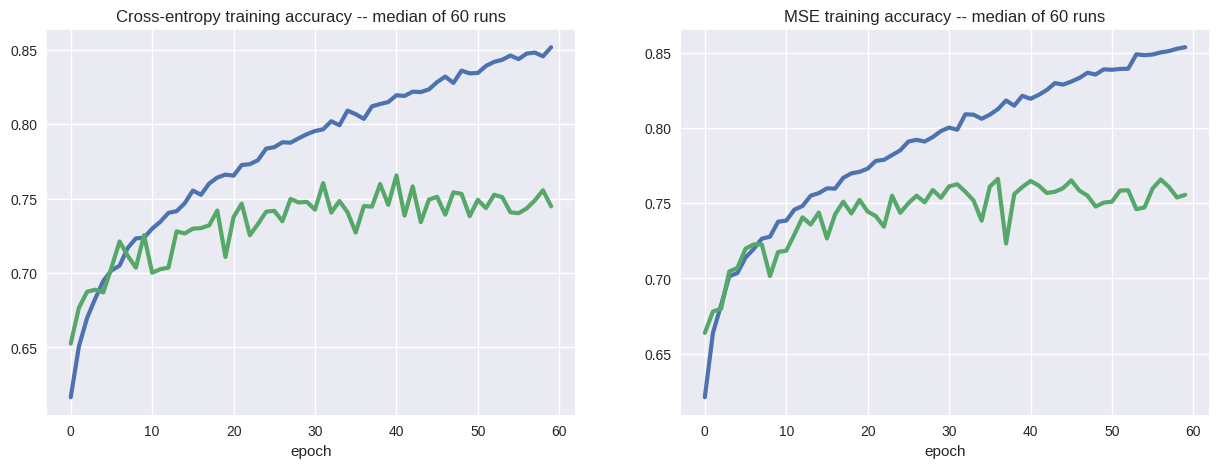

In [ ]:
# np.mean(histories_X[0.01][1].history['val_accuracy'])

epochs = 60

fig,axs=plt.subplots(1,2,figsize=(15,5))
axs=axs.flat


losses_X = np.median([history.history['accuracy'] for history in histories_X_optimal.values()], axis = 0)
val_losses_X = np.median([history.history['val_accuracy'] for history in histories_X_optimal.values()], axis = 0)

axs[0].plot(losses_X,linewidth=3)
axs[0].plot(val_losses_X,linewidth=3)
axs[0].set_title("Cross-entropy training accuracy -- median of {} runs".format(epochs))
axs[0].set_xlabel("epoch")


losses_MSE = np.median([history.history['accuracy'] for history in histories_MSE_optimal.values()], axis = 0)
val_losses_MSE = np.median([history.history['val_accuracy'] for history in histories_MSE_optimal.values()], axis = 0)

axs[1].plot(losses_MSE,label="sq loss, double lr",linewidth=3)
axs[1].plot(val_losses_MSE,label="sq loss, double lr",linewidth=3)
axs[1].set_title("MSE training accuracy -- median of {} runs".format(epochs))
axs[1].set_xlabel("epoch")





NameError: name 'acc_X' is not defined

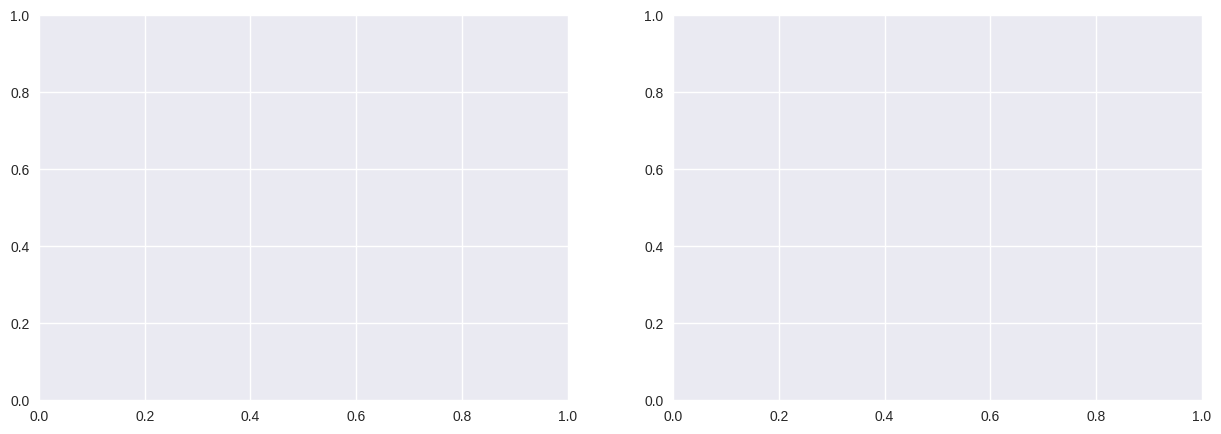

In [ ]:



fig,axs=plt.subplots(1,2,figsize=(15,5))
axs=axs.flat

ymin=min(min(acc_X),min(acc_mse))*0.995
ymax=max(max(acc_X),max(acc_mse))*1.005

ax=axs[0]
ax.plot(acc_X,label="cross entropy",linewidth=3)
ax.plot(acc_mse,label="square loss",linewidth=3)
ax.set_title("training accuracy -- median of {} runs".format(epochs))
ax.set_xlabel("epoch")
ax.set_ylim(ymin,ymax)
ax.legend()

ax=axs[1]
ax.plot(np.median(results["val_acc_cross_entropy"],axis=0),label="cross entropy",linewidth=3)
ax.plot(np.median(results["val_acc_mse"],axis=0),label="square loss",linewidth=3)
ax.set_title("test accuracy -- median of {} runs".format(epochs))
ax.set_xlabel("epoch")
ax.set_ylim(ymin,ymax)
ax.legend()

In [ ]:
def plot_grads(layer,ax):
    grad_norms=np.median(results["grad_norms_cross_entropy"][:,:,layer],axis=0)
    epochs=results["grad_norms_cross_entropy"].shape[1]
    ax.plot(grad_norms,label="cross entropy",linewidth=3)
    grad_norms=np.median(results["grad_norms_mse"][:,:,layer],axis=0)
    ax.plot(grad_norms,label="square loss",linewidth=3)


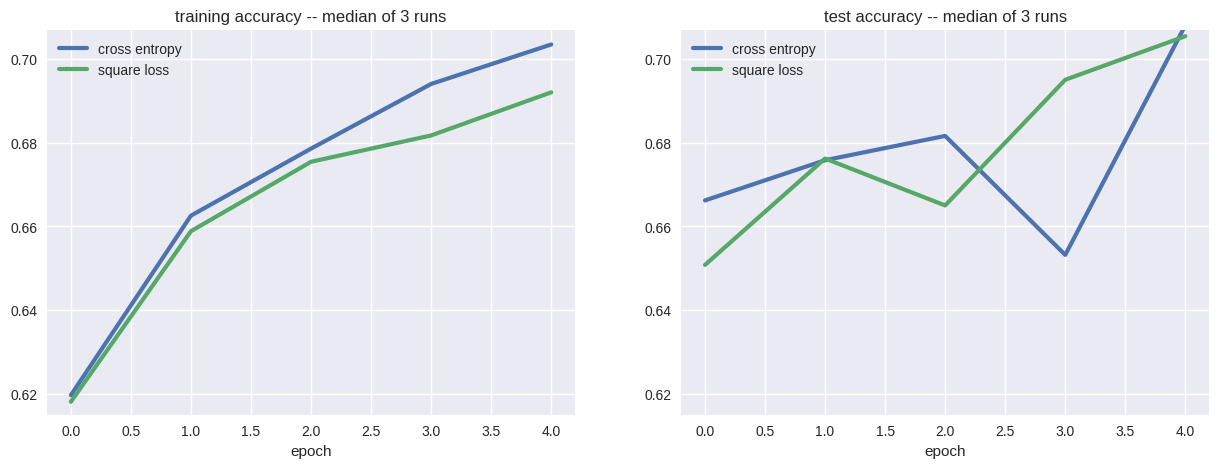

In [ ]:


epochs=len(results["acc_cross_entropy"])

acc_X=np.median(results["acc_cross_entropy"],axis=0)
acc_mse=np.median(results["acc_mse"],axis=0)
ymin=min(min(acc_X),min(acc_mse))*0.995
ymax=max(max(acc_X),max(acc_mse))*1.005

fig,axs=plt.subplots(1,2,figsize=(15,5))
axs=axs.flat



ax=axs[0]
ax.plot(acc_X,label="cross entropy",linewidth=3)
ax.plot(acc_mse,label="square loss",linewidth=3)
ax.set_title("training accuracy -- median of {} runs".format(epochs))
ax.set_xlabel("epoch")
ax.set_ylim(ymin,ymax)
ax.legend()

ax=axs[1]
ax.plot(np.median(results["val_acc_cross_entropy"],axis=0),label="cross entropy",linewidth=3)
ax.plot(np.median(results["val_acc_mse"],axis=0),label="square loss",linewidth=3)
ax.set_title("test accuracy -- median of {} runs".format(epochs))
ax.set_xlabel("epoch")
ax.set_ylim(ymin,ymax)
ax.legend()
